Coding Assignment: NYC Taxi Data Analysis

Dataset

Use the Seaborn taxis dataset from seaborn

*Problem Statement*:

You are working as a Data Analyst for a taxi company. Analyze the taxi dataset using Pandas, Matplotlib, and Seaborn to understand customer behavior, trip patterns, revenue, payment preferences, and tipping behavior.

For each question, perform the required analysis, choose a suitable visualization, customize the plot, and write 1–2 meaningful observations from the visualization.


# Part 1

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#1)
taxis=sns.load_dataset("taxis")
display(taxis.head(5))

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [69]:
#2) 
print(taxis.shape)
print(taxis["payment"].value_counts())

(6433, 14)
payment
credit card    4577
cash           1812
Name: count, dtype: int64


In [18]:
#3) numerical-distance,fare,tip,tolls,total,passengers categorical-color-dropoff_borough
display(taxis.columns)
taxis.info()
print(taxis.isna().sum())
print(taxis.select_dtypes(include="number").columns)
print(taxis.select_dtypes(include=["object","category"]).columns)

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [ ]:
#6)
display(taxis.describe())


,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223616,2019-03-16 08:45:49.491217408,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


# Part 2

pickup_zone
Midtown Center                  230
Upper East Side South           211
Penn Station/Madison Sq West    210
Clinton East                    208
Midtown East                    198
                               ... 
Ozone Park                        1
Glendale                          1
Woodlawn/Wakefield                1
West Farms/Bronx River            1
Hillcrest/Pomonok                 1
Name: count, Length: 194, dtype: int64
Highest pickup zone: Midtown Center
Number of trips: 230


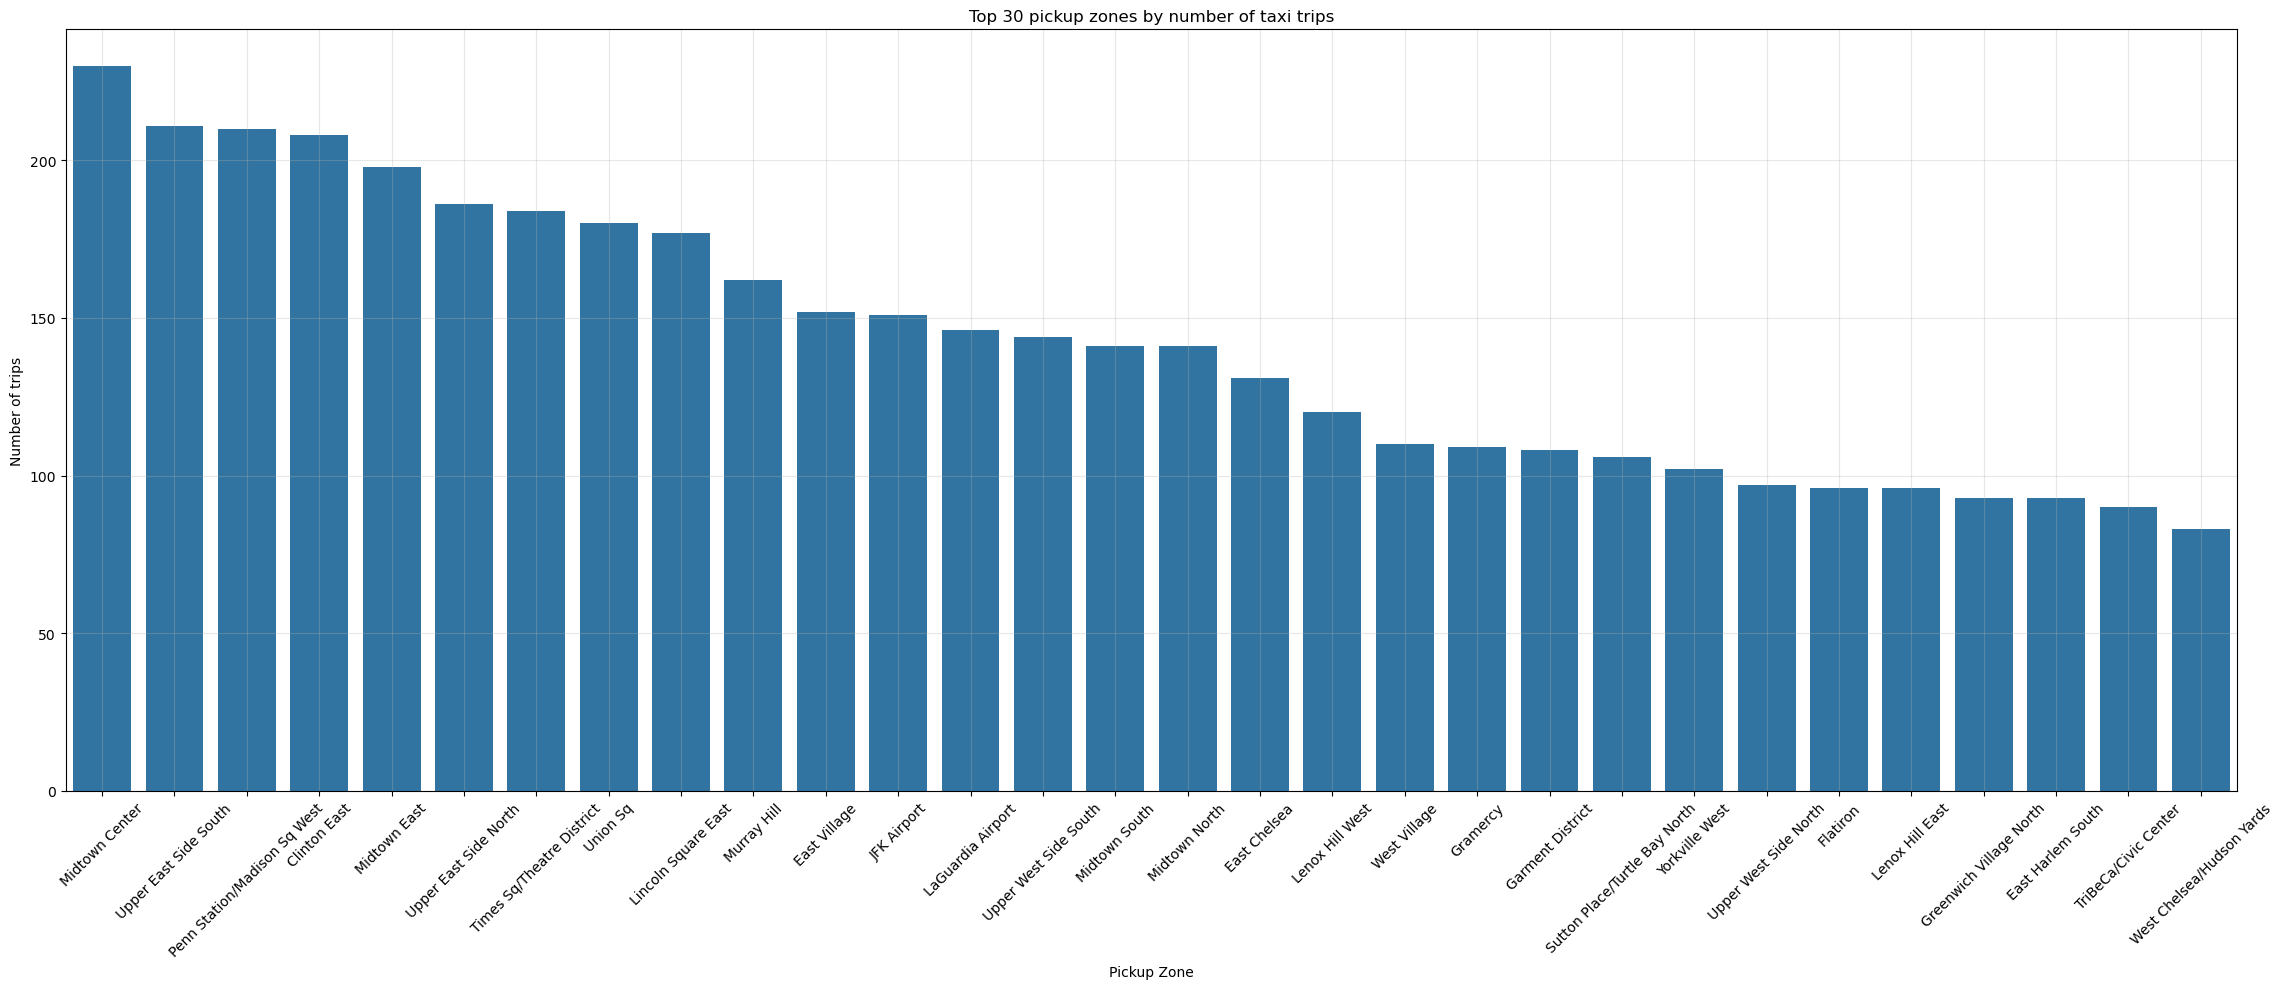

In [ ]:
#7)
pickup_zone_counts=taxis["pickup_zone"].value_counts()
print(pickup_zone_counts)
print("Highest pickup zone:", pickup_zone_counts.idxmax())
print("Number of trips:", pickup_zone_counts.max() )

plt.figure(figsize=(23,10))
sns.barplot(x=pickup_zone_counts.head(30).index,y=pickup_zone_counts.head(30).values)

plt.title("Top 30 pickup zones by number of taxi trips")
plt.xlabel("Pickup Zone")
plt.ylabel("Number of trips")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

 Bar plot shows the top 10 pickup zones based on the number of taxi trips. Midtown center has the tallest bar and has the highest number of taxi pickups.

dropoff_zone
Upper East Side North    245
Murray Hill              220
Midtown Center           215
Upper East Side South    177
Midtown East             176
                        ... 
Queensboro Hill            1
Homecrest                  1
Madison                    1
Morrisania/Melrose         1
Brooklyn Navy Yard         1
Name: count, Length: 203, dtype: int64
Highest dropoff zone: Upper East Side North
Number of trips: 245


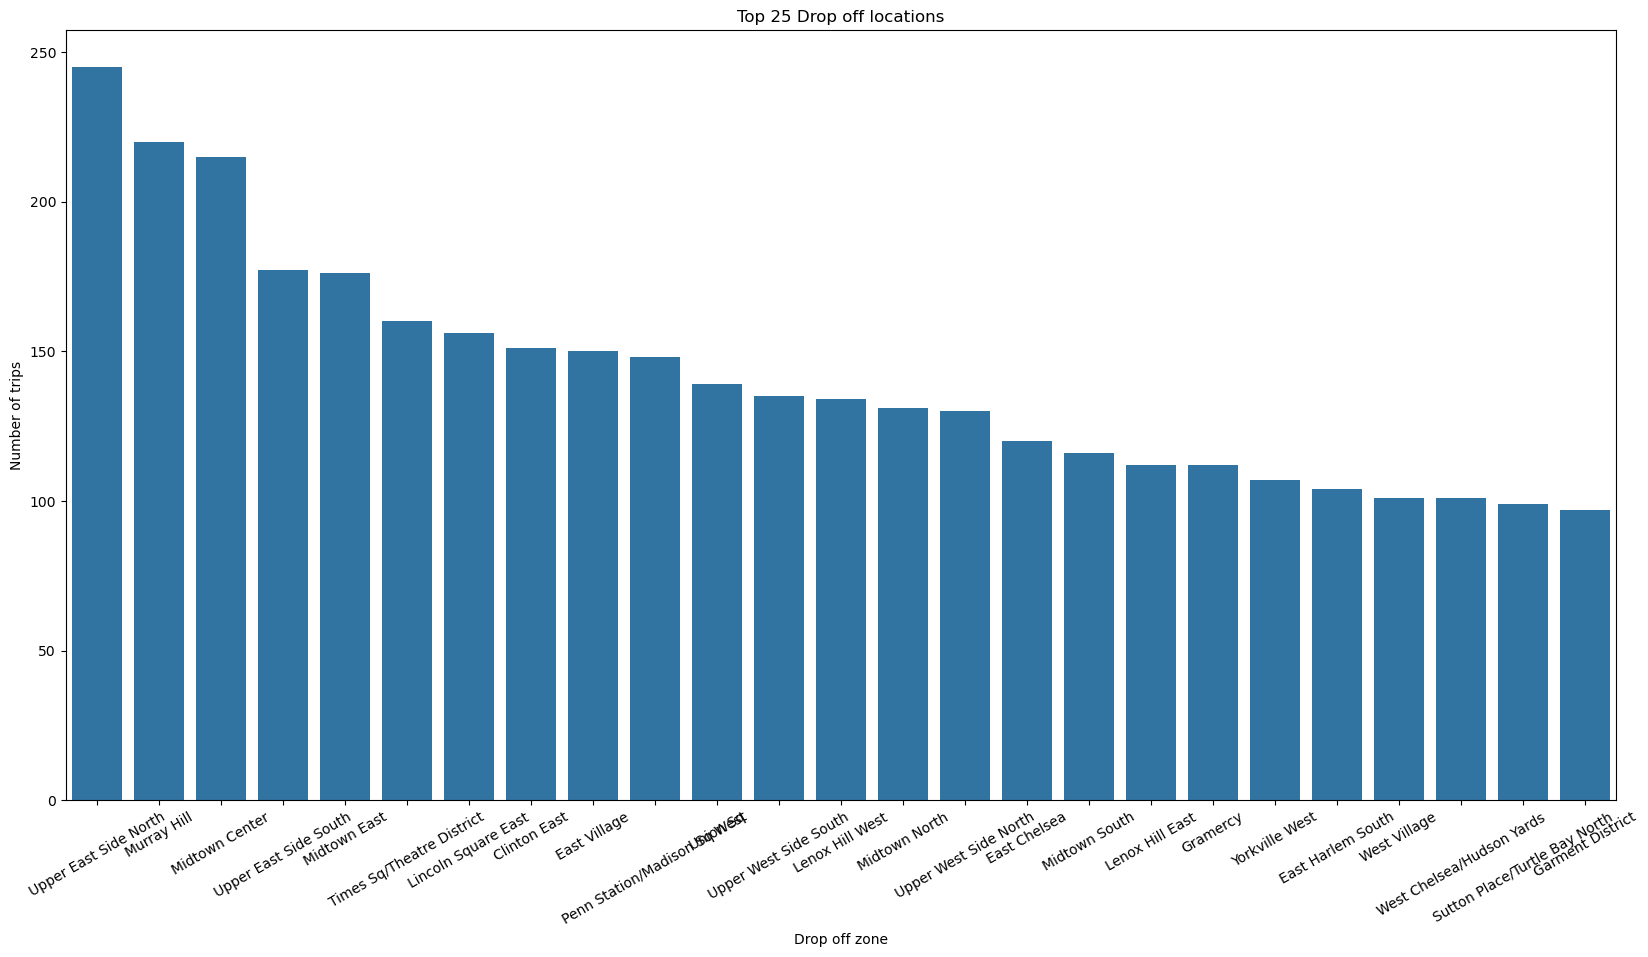

In [20]:
#8)
dropoff_counts=taxis["dropoff_zone"].value_counts()
print(dropoff_counts)
print("Highest dropoff zone:",dropoff_counts.idxmax())
print("Number of trips:",dropoff_counts.max())

plt.figure(figsize=(20,10))
sns.barplot(x=dropoff_counts.head(25).index,y=dropoff_counts.head(25).values)
plt.title("Top 25 Drop off locations")
plt.xlabel("Drop off zone")
plt.ylabel("Number of trips")
plt.xticks(rotation=30)
plt.show()

busiest destination is Upper East Side North

payment
credit card    4577
cash           1812
Name: count, dtype: int64
Highest used payment method: credit card
Number of trips: 4577


C:\Users\user\AppData\Local\Temp\ipykernel_14376\2802753551.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=taxis,x="payment",palette="Set2")


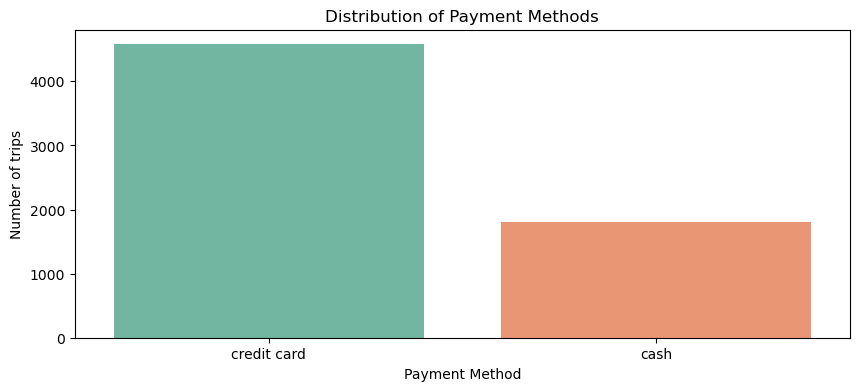

Percentage: 71.64 %


In [36]:
#9)
payment_counts=taxis["payment"].value_counts()
print(payment_counts)
print("Highest used payment method:",payment_counts.idxmax())
print("Number of trips:",payment_counts.max())

plt.figure(figsize=(10,4))
sns.countplot(data=taxis,x="payment",palette="Set2")
plt.title("Distribution of Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of trips")
plt.show()

percentage=(payment_counts.max()/payment_counts.sum())*100
print("Percentage:",round(percentage,2),"%")

C:\Users\user\AppData\Local\Temp\ipykernel_14376\430961154.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=payment_counts.index,y=payment_counts.values,palette="Set2")


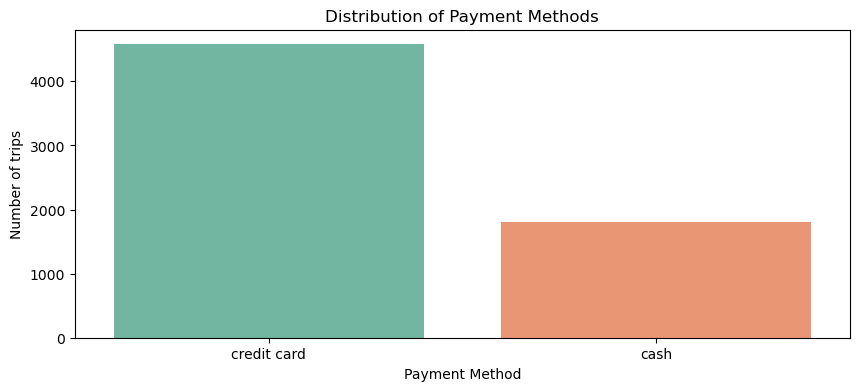

In [37]:
# barplot
plt.figure(figsize=(10,4))
sns.barplot(x=payment_counts.index,y=payment_counts.values,palette="Set2")
plt.title("Distribution of Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of trips")
plt.show()

payment
cash           11.592991
credit card    13.694750
Name: fare, dtype: float64


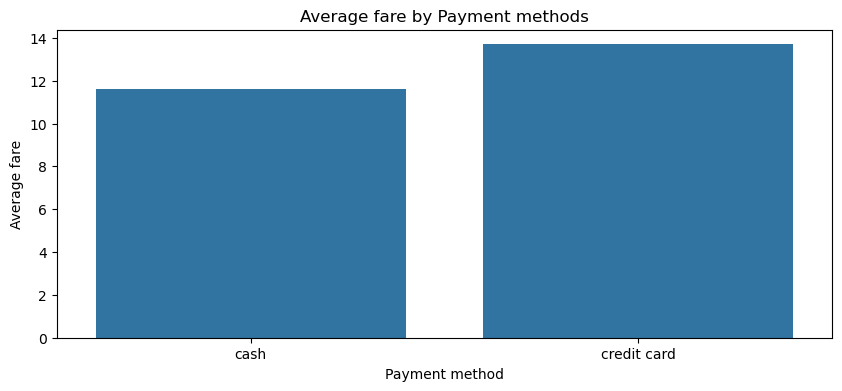

Payment method with highest average fare: credit card
Highest average fare: 13.694749836137209
Most frequently used payment method: credit card


In [44]:
#10)
avg_fare=taxis.groupby("payment")["fare"].mean()
print(avg_fare)

plt.figure(figsize=(10,4))
sns.barplot(x=avg_fare.index,y=avg_fare.values)
plt.title("Average fare by Payment methods")
plt.xlabel("Payment method")
plt.ylabel("Average fare")
plt.show()

print("Payment method with highest average fare:",avg_fare.idxmax())
print("Highest average fare:",avg_fare.max())

payment_counts=taxis["payment"].value_counts()
print("Most frequently used payment method:",payment_counts.idxmax())

yes, the most frequently used payment method is credit card and it is also the one with the highest average fare.

pickup_zone
Allerton/Pelham Gardens     64.66
Alphabet City              107.50
Astoria                    514.50
Auburndale                  21.40
Battery Park                19.00
                            ...  
Woodlawn/Wakefield          23.53
Woodside                   289.00
World Trade Center         385.50
Yorkville East             712.00
Yorkville West             980.00
Name: fare, Length: 194, dtype: float64


C:\Users\user\AppData\Local\Temp\ipykernel_14376\1112493818.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_revenue.sort_values(ascending=False).head(15).index,y=total_revenue.sort_values(ascending=False).head(15).values,palette="viridis")


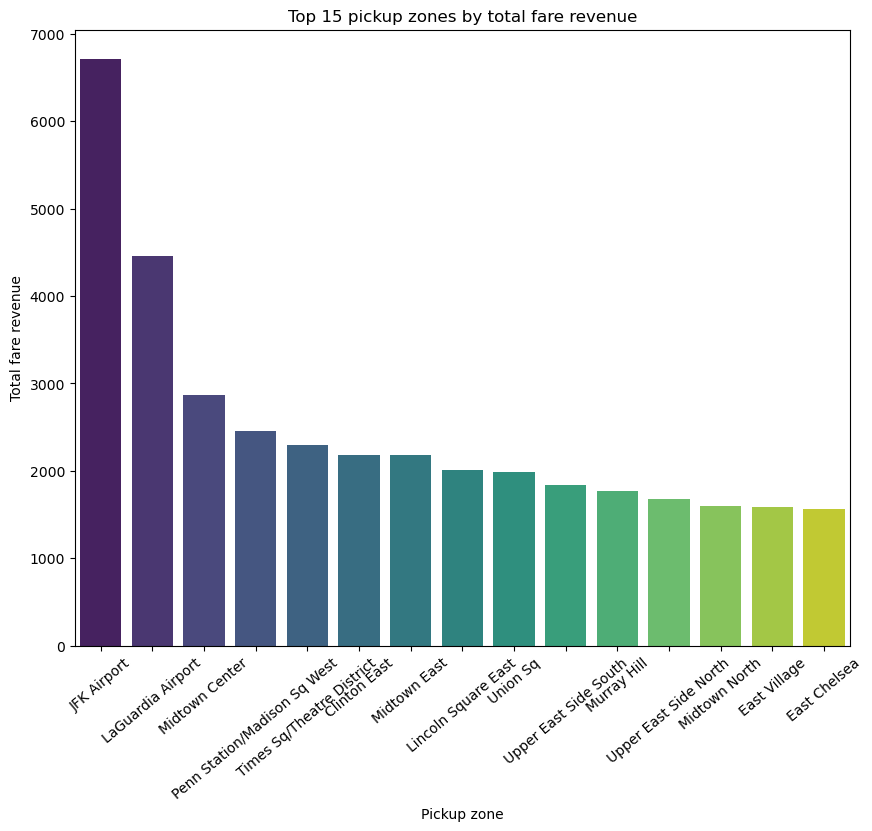

Highest revenue pickup zone: JFK Airport
Total fare revenue: 6713.06


In [48]:
#11)
total_revenue=taxis.groupby("pickup_zone")["fare"].sum()
print(total_revenue)
plt.figure(figsize=(10,8))
sns.barplot(x=total_revenue.sort_values(ascending=False).head(15).index,y=total_revenue.sort_values(ascending=False).head(15).values,palette="viridis")
plt.title("Top 15 pickup zones by total fare revenue")
plt.xlabel("Pickup zone")
plt.ylabel("Total fare revenue")
plt.xticks(rotation=40)
plt.show()

print("Highest revenue pickup zone:",total_revenue.idxmax())
print("Total fare revenue:",total_revenue.max())

JFK Airport has the highest bar and it is the highest revenue pickup zone.

payment
cash           0.000000
credit card    2.781805
Name: tip, dtype: float64


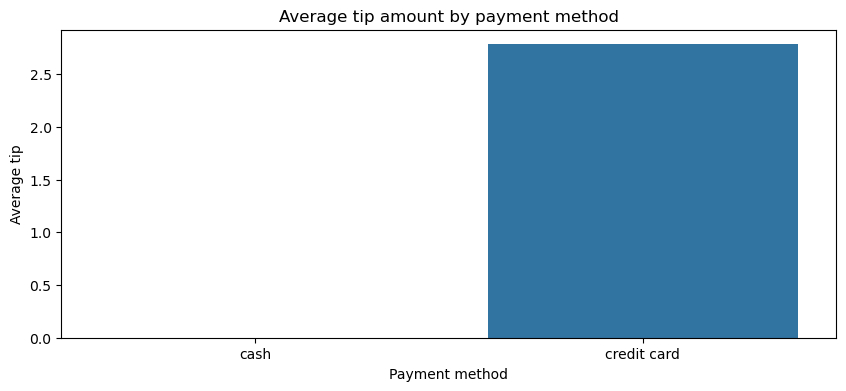

Payment method with highest average tip: credit card
Highest average tip: 2.781804675551671


In [51]:
#12)
avg_tip=taxis.groupby("payment")["tip"].mean()
print(avg_tip)

plt.figure(figsize=(10,4))
sns.barplot(x=avg_tip.index,y=avg_tip.values)
plt.title("Average tip amount by payment method")
plt.xlabel("Payment method")
plt.ylabel("Average tip")
plt.show()

print("Payment method with highest average tip:",avg_tip.idxmax())
print("Highest average tip:",avg_tip.max())

credit card payment has the highest average tip amount.

# Part 3

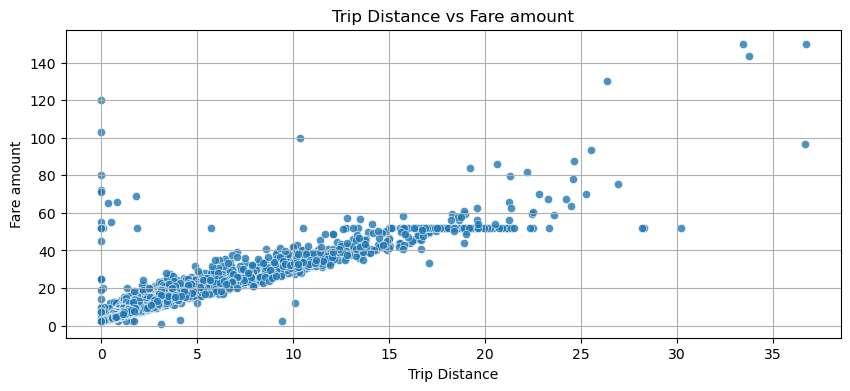

In [57]:
#13)
plt.figure(figsize=(10,4))
sns.scatterplot(data=taxis,x="distance",y="fare",s=35,alpha=0.8)
plt.title("Trip Distance vs Fare amount")
plt.xlabel("Trip Distance")
plt.ylabel("Fare amount")
plt.grid()
plt.show()

 yes,there exists a positive relationship between trip distance and fare ,as distance increases fare increases. 
 
yes,some unusual observations are present,including short distance trips with high fares and longer trips with low fares and few points have fares above 120.

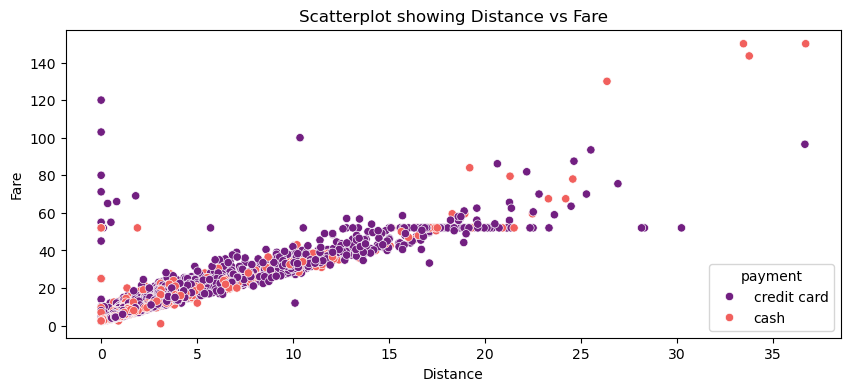

In [58]:
#14)
plt.figure(figsize=(10,4))
sns.scatterplot(data=taxis,x="distance",y="fare",hue="payment",palette="magma")
plt.title("Scatterplot showing Distance vs Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.show()

credit card payment appears more frequently than cash payments.

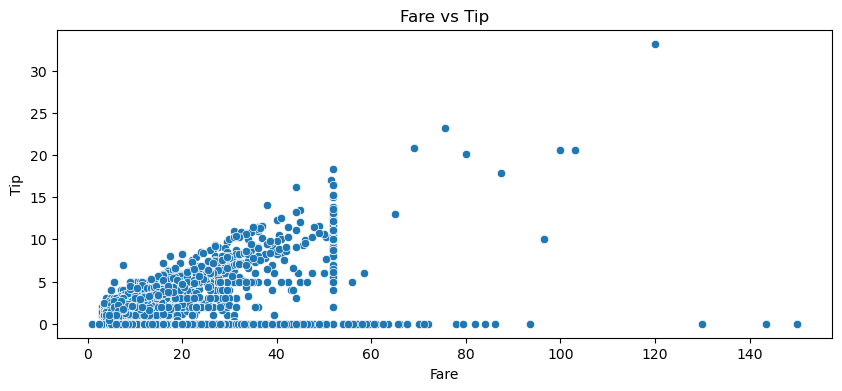

Correlation: 0.4886124004721826


In [ ]:
#15)
plt.figure(figsize=(10,4))
sns.scatterplot(data=taxis,x="fare",y="tip")
plt.title("Fare vs Tip")
plt.xlabel("Fare")
plt.ylabel("Tip")
plt.show()

#print("Correlation:",taxis["fare"].corr(taxis["tip"]))

NO, higher fare does not alway result in a higher tip.

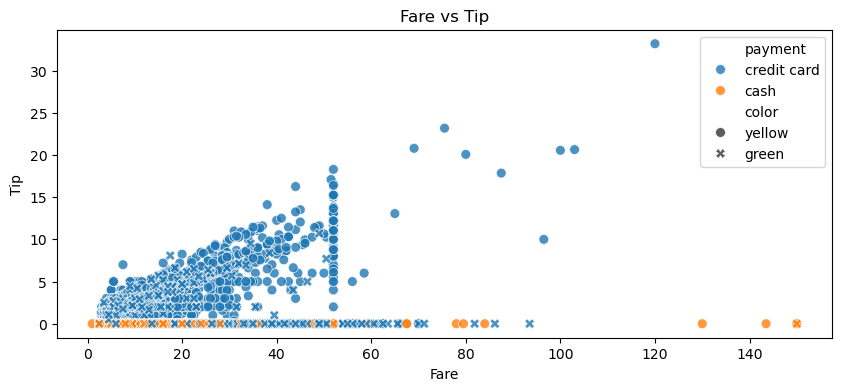

In [63]:
#16)
plt.figure(figsize=(10,4))
sns.scatterplot(data=taxis,x="fare",y="tip",hue="payment",style="color",s=50,alpha=0.8)
plt.title("Fare vs Tip")
plt.xlabel("Fare")
plt.ylabel("Tip")
plt.show()

credit  card transactions show a wider range of tip amounts,while cash transactions are mosly concentrated near zero tips.

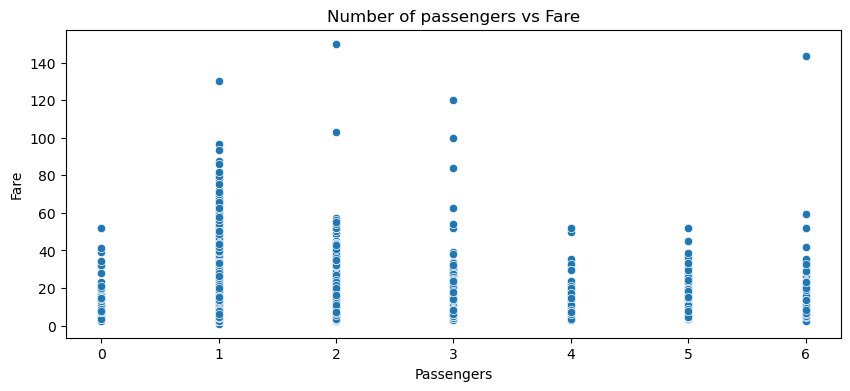

In [66]:
#17)
plt.figure(figsize=(10,4))
sns.scatterplot(data=taxis,x="passengers",y="fare")
plt.title("Number of passengers vs Fare")
plt.xlabel("Passengers")
plt.ylabel("Fare")
plt.show()

No,the number of passengers does not influence the fare. Fares vary considerably across different passenger counts.

# Part 4

payment
credit card    4577
cash           1812
Name: count, dtype: int64


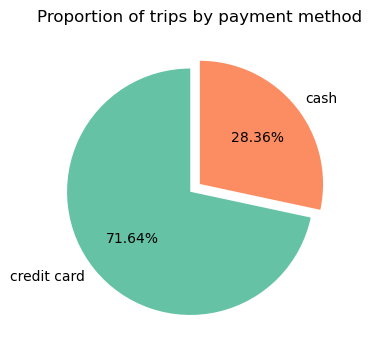

In [71]:
#18)
payment_counts=taxis["payment"].value_counts()
print(payment_counts)
largest=payment_counts.values.argmax()
explode=[0,0]
explode[largest]=0.1
plt.figure(figsize=(10,4))
plt.pie(payment_counts.values,labels=payment_counts.index,autopct="%.2f%%",explode=explode,startangle=90,colors=sns.color_palette("Set2"))
plt.title("Proportion of trips by payment method")
plt.show()

credit card represents the largest share of tips.

color
yellow    5451
green      982
Name: count, dtype: int64


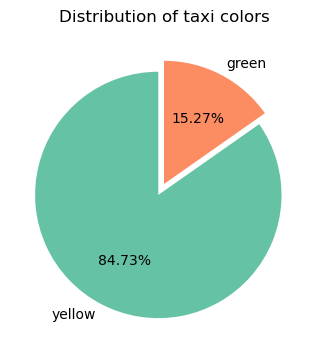

In [74]:
#19)
color_counts=taxis["color"].value_counts()
print(color_counts)
largest=color_counts.values.argmax()
explode=[0,0]
explode[largest]=0.1
plt.figure(figsize=(10,4))
plt.pie(color_counts.values,labels=color_counts.index,autopct="%.2f%%",explode=explode,startangle=90,colors=sns.color_palette("Set2"))
plt.title("Distribution of taxi colors")
plt.show()

yellow taxi type dominates the dataset.

passengers
1    4678
2     876
5     277
3     243
6     153
4     110
0      96
Name: count, dtype: int64


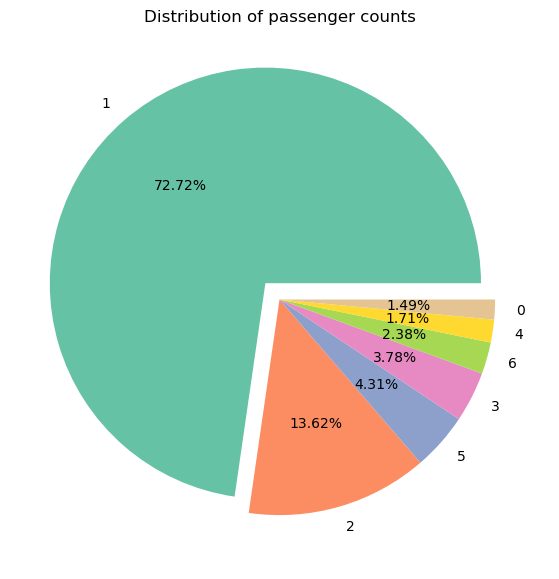

In [81]:
#20)
passenger_counts=taxis["passengers"].value_counts()
print(passenger_counts)
largest=passenger_counts.values.argmax()
explode=[0,0,0,0,0,0,0]
explode[largest]=0.1
plt.figure(figsize=(9,7))
plt.pie(passenger_counts.values,labels=passenger_counts.index,autopct="%.2f%%",explode=explode,colors=sns.color_palette("Set2"))
plt.title("Distribution of passenger counts")
plt.show()

the largest slice represents the most common passenger group i.e., the single passenger.

# Part 5

               pickup  pickup_hour
0 2019-03-23 20:21:09           20
1 2019-03-04 16:11:55           16
2 2019-03-27 17:53:01           17
3 2019-03-10 01:23:59            1
4 2019-03-30 13:27:42           13
pickup_hour
0     205
1     110
2     101
3      67
4      57
5      51
6     142
7     221
8     313
9     319
10    325
11    295
12    334
13    316
14    360
15    330
16    336
17    388
18    417
19    406
20    368
21    355
22    321
23    296
Name: count, dtype: int64


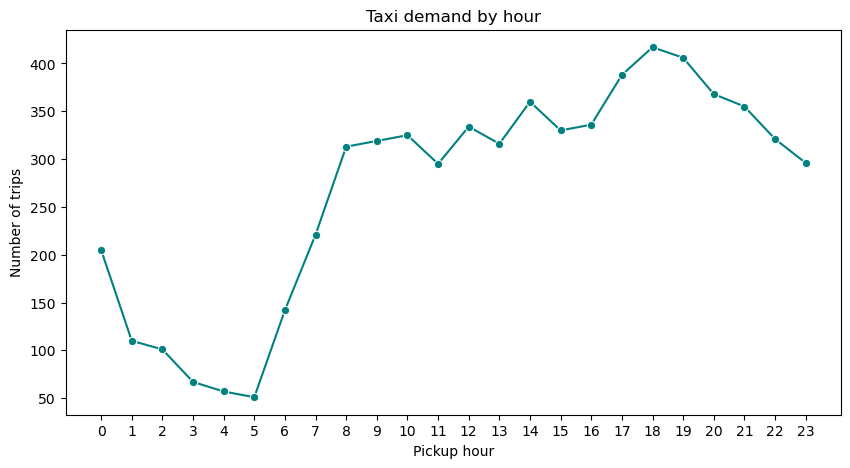

In [84]:
#21)
taxis["pickup_hour"]=taxis["pickup"].dt.hour
print(taxis[["pickup","pickup_hour"]].head())
hourly_trips=taxis["pickup_hour"].value_counts().sort_index()
print(hourly_trips)

plt.figure(figsize=(10,5))
sns.lineplot(x=hourly_trips.index,y=hourly_trips.values,marker="o",color="teal")
plt.title("Taxi demand by hour")
plt.xlabel("Pickup hour")
plt.ylabel("Number of trips")
plt.xticks(range(0,24))
plt.show()

the number of trips fluctuates across different hours, hour with the highest number of trips represent the peak taxi demand period and vice versa.

               pickup  pickup_hour
0 2019-03-23 20:21:09           20
1 2019-03-04 16:11:55           16
2 2019-03-27 17:53:01           17
3 2019-03-10 01:23:59            1
4 2019-03-30 13:27:42           13
pickup_hour
0     14.039024
1     12.150000
2     12.069307
3     12.470149
4     15.447368
5     16.774510
6     13.296761
7     13.099729
8     12.224473
9     12.865423
10    12.994985
11    12.738847
12    13.496018
13    12.506297
14    13.929556
15    14.088091
16    14.826190
17    13.723995
18    12.362206
19    12.196232
20    12.083560
21    13.040479
22    12.446449
23    13.199358
Name: fare, dtype: float64


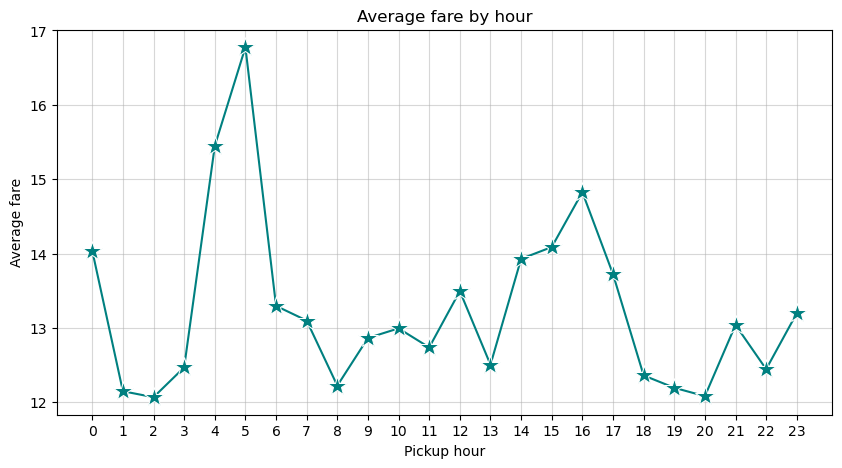

In [93]:
#22)
taxis["pickup_hour"]=taxis["pickup"].dt.hour
print(taxis[["pickup","pickup_hour"]].head())
avg_fare=taxis.groupby("pickup_hour")["fare"].mean()
print(avg_fare)

plt.figure(figsize=(10,5))
sns.lineplot(x=avg_fare.index,y=avg_fare.values,marker="*",markersize=15,color="teal")
plt.title("Average fare by hour")
plt.xlabel("Pickup hour")
plt.ylabel("Average fare")
plt.xticks(range(0,24))
plt.grid(alpha=0.5)
plt.show()


average fare fluctuates throughout the day,and at 5 figure shows a peak average fare and at 20 figure shows the lowest average fare.

               pickup  pickup_hour
0 2019-03-23 20:21:09           20
1 2019-03-04 16:11:55           16
2 2019-03-27 17:53:01           17
3 2019-03-10 01:23:59            1
4 2019-03-30 13:27:42           13
pickup_hour
0     2.192829
1     2.027182
2     1.691287
3     1.614776
4     2.394912
5     2.910784
6     1.523732
7     1.833891
8     1.783994
9     1.837931
10    1.875385
11    1.738712
12    1.944491
13    1.932722
14    1.743556
15    2.105879
16    2.075685
17    1.962036
18    1.998489
19    2.122365
20    2.056114
21    2.119944
22    2.195732
23    2.217669
Name: tip, dtype: float64


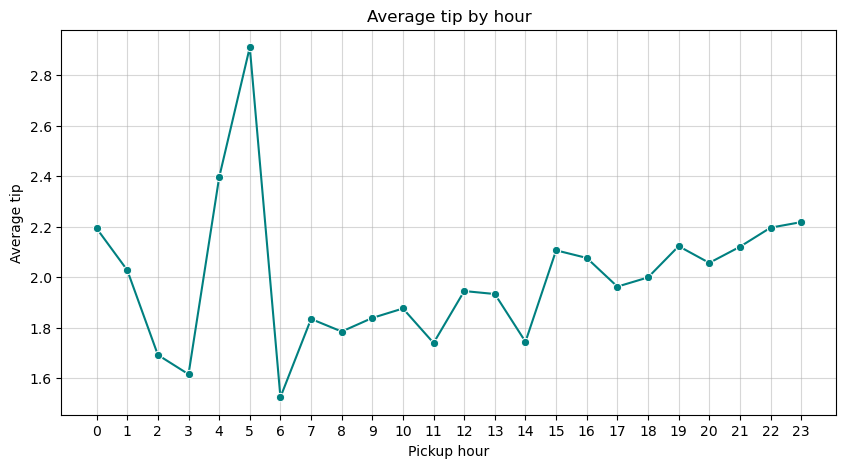

In [94]:
#23)
taxis["pickup_hour"]=taxis["pickup"].dt.hour
print(taxis[["pickup","pickup_hour"]].head())
avg_tip=taxis.groupby("pickup_hour")["tip"].mean()
print(avg_tip)

plt.figure(figsize=(10,5))
sns.lineplot(x=avg_tip.index,y=avg_tip.values,marker="o",color="teal")
plt.title("Average tip by hour")
plt.xlabel("Pickup hour")
plt.ylabel("Average tip")
plt.xticks(range(0,24))
plt.grid(alpha=0.5)
plt.show()


from around 3 to 5 am,average tip increases then a sudden decline occurs at 6 then from 7 figure shows an upward pattern.

# Part 6

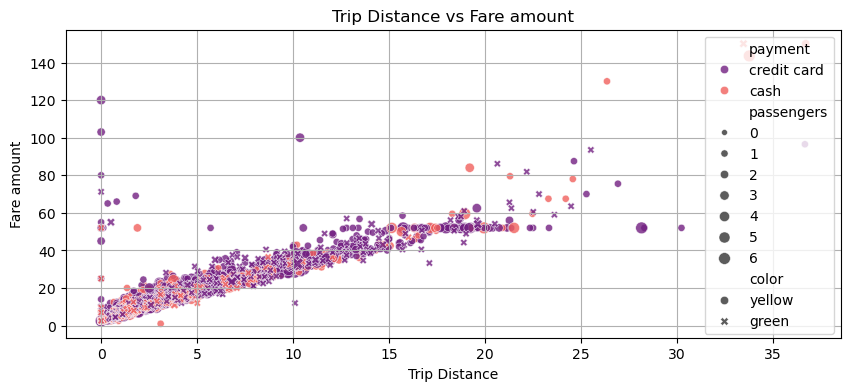

In [96]:
#24)
plt.figure(figsize=(10,4))
sns.scatterplot(data=taxis,x="distance",y="fare",size="passengers",alpha=0.8,hue="payment",style="color",palette="magma")
plt.title("Trip Distance vs Fare amount")
plt.xlabel("Trip Distance")
plt.ylabel("Fare amount")
plt.grid()
plt.show()

Fare generally increases as trip distance increases. Both cash and credit card transactions occur across different distances and fares.

Yellow and green taxis are represented by different marker shapes.

Marker sizes help compare trips with different passenger counts.Some trips have unusually high fares despite relatively short distances.

pickup_zone
Allerton/Pelham Gardens    32.330000
Alphabet City              11.944444
Astoria                     7.915385
Auburndale                 21.400000
Battery Park               19.000000
                             ...    
Woodlawn/Wakefield         23.530000
Woodside                   11.115385
World Trade Center         16.062500
Yorkville East             10.028169
Yorkville West              9.607843
Name: fare, Length: 194, dtype: float64


C:\Users\user\AppData\Local\Temp\ipykernel_14376\3513482518.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_fare_location.sort_values(ascending=False).head(15).index,y=avg_fare_location.sort_values(ascending=False).head(15).values,palette='viridis')


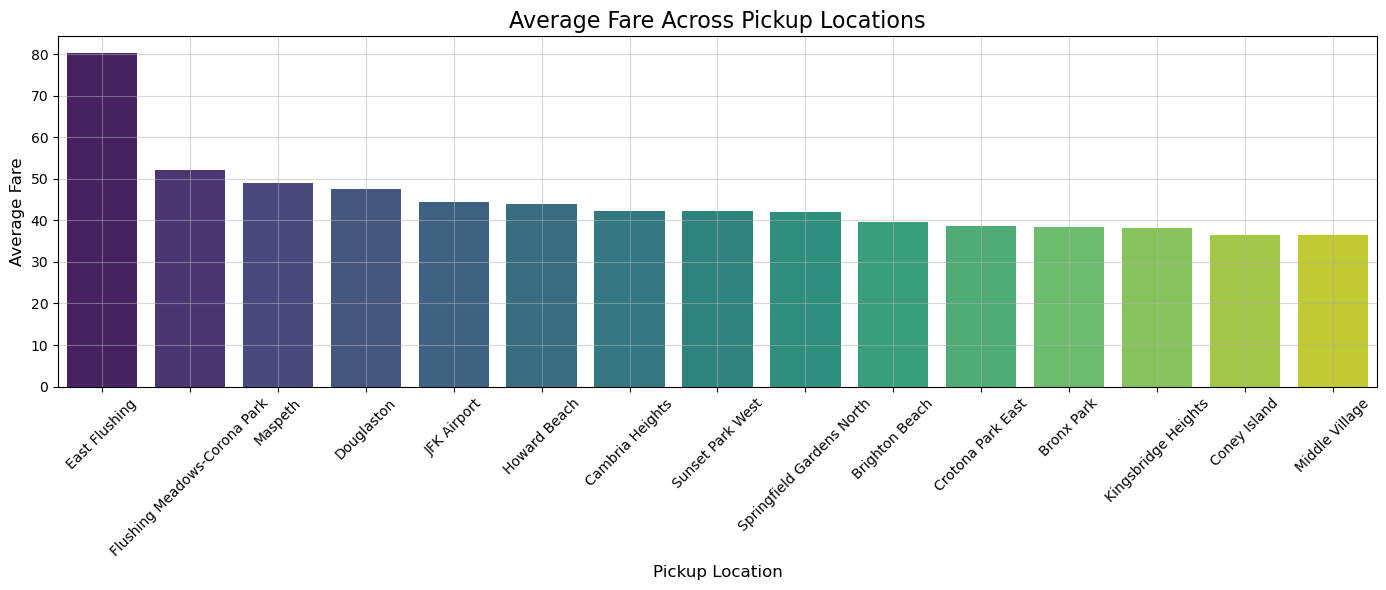

Highest average fare location: East Flushing
Highest average fare: 80.25


In [101]:
#25)
avg_fare_location = taxis.groupby("pickup_zone")["fare"].mean()
print(avg_fare_location)

plt.figure(figsize=(14, 6))
sns.barplot(x=avg_fare_location.sort_values(ascending=False).head(15).index,y=avg_fare_location.sort_values(ascending=False).head(15).values,palette='viridis')
plt.title("Average Fare Across Pickup Locations", fontsize=16)
plt.xlabel("Pickup Location", fontsize=12)
plt.ylabel("Average Fare", fontsize=12)
plt.xticks(rotation=45, )
plt.grid( alpha=0.5)
plt.tight_layout()
plt.show()
print("Highest average fare location:",avg_fare_location.idxmax())

print("Highest average fare:",(avg_fare_location.max()))

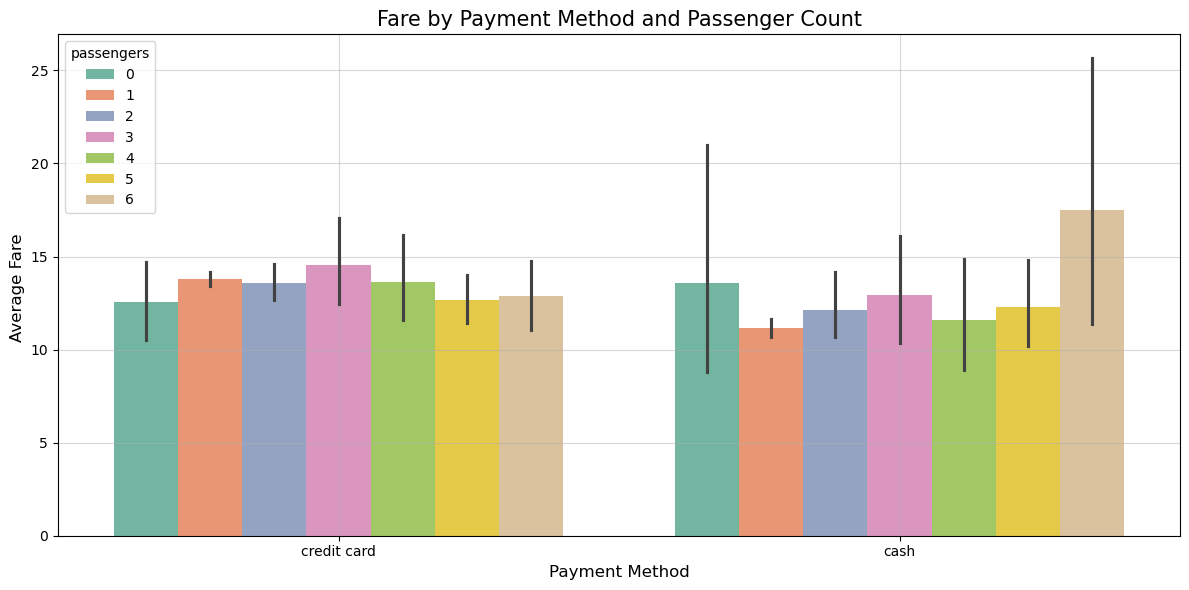

In [103]:
#26)
plt.figure(figsize=(12, 6))
sns.barplot(data=taxis, x="payment",y="fare",hue="passengers",palette="Set2")
plt.title("Fare by Payment Method and Passenger Count", fontsize=15)
plt.xlabel("Payment Method", fontsize=12)
plt.ylabel("Average Fare ", fontsize=12)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

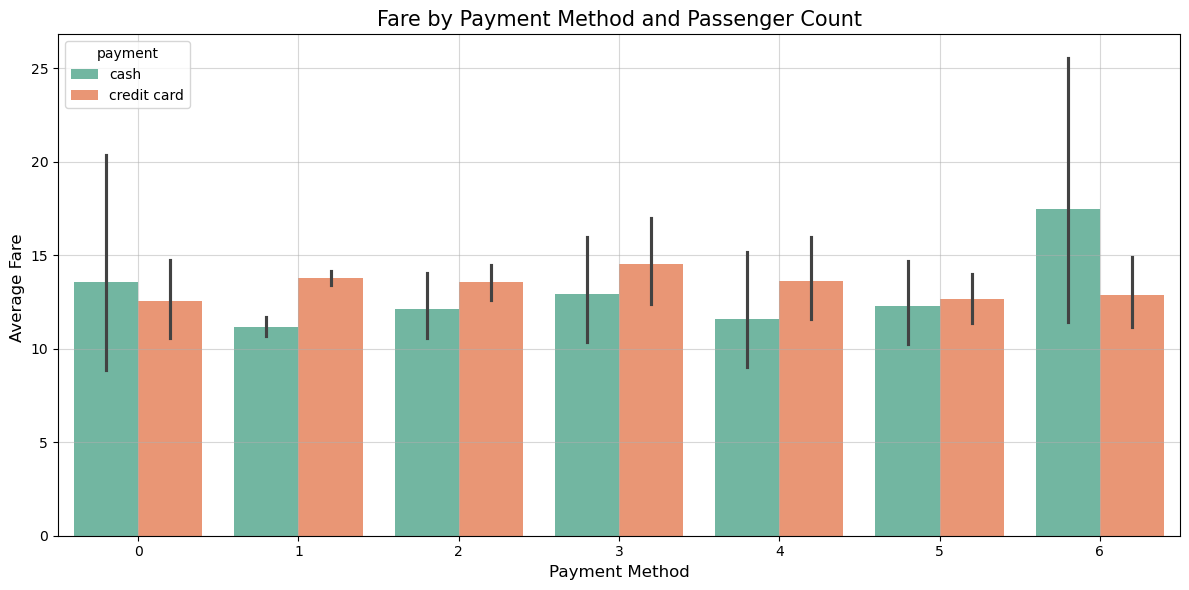

In [104]:
plt.figure(figsize=(12, 6))
sns.barplot(data=taxis, x="passengers",y="fare",hue="payment",palette="Set2")
plt.title("Fare by Payment Method and Passenger Count", fontsize=15)
plt.xlabel("Payment Method", fontsize=12)
plt.ylabel("Average Fare ", fontsize=12)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

# Part 7

In [ ]:
#27)
pickup_location_counts=taxis["pickup_zone"].value_counts()
print(pickup_location_counts)
print("Pickup location with the highest number of trips:",pickup_location.idxmax()) # Midtown center

pickup_zone
Midtown Center                  230
Upper East Side South           211
Penn Station/Madison Sq West    210
Clinton East                    208
Midtown East                    198
                               ... 
Ozone Park                        1
Glendale                          1
Woodlawn/Wakefield                1
West Farms/Bronx River            1
Hillcrest/Pomonok                 1
Name: count, Length: 194, dtype: int64
Pickup location with the highest number of trips: Midtown Center


In [ ]:
#28)
total_revenue=taxis.groupby("pickup_zone")["fare"].sum()
print(total_revenue)
print("Pickup location with highest total fare revenue:",total_revenue.idxmax()) #  JFK Airport

pickup_zone
Allerton/Pelham Gardens     64.66
Alphabet City              107.50
Astoria                    514.50
Auburndale                  21.40
Battery Park                19.00
                            ...  
Woodlawn/Wakefield          23.53
Woodside                   289.00
World Trade Center         385.50
Yorkville East             712.00
Yorkville West             980.00
Name: fare, Length: 194, dtype: float64
Pickup location with highest total fare revenue: JFK Airport


In [111]:
#29)
highest_trips_location=pickup_location_counts.idxmax()
highest_revenue_location=total_revenue.idxmax()
if highest_trips_location == highest_revenue_location:
    print("Yes, both locations are the same")
else:
    print("No, both are different")

No, both are different


In [112]:
#30)
payment_counts=taxis["payment"].value_counts()
print(payment_counts)
print("Most popular payment method:",payment_counts.idxmax())

payment
credit card    4577
cash           1812
Name: count, dtype: int64
Most popular payment method: credit card


In [114]:
#31)
avg_fare=taxis.groupby("payment")["fare"].mean()
print(avg_fare)
print("Payment method with highest average fare:",avg_fare.idxmax())

payment
cash           11.592991
credit card    13.694750
Name: fare, dtype: float64
Payment method with highest average fare: credit card


In [116]:
#32)
avg_tip=taxis.groupby("payment")["tip"].mean()
print(avg_tip)
print("Payment method with highest average tip:",avg_tip.idxmax())

payment
cash           0.000000
credit card    2.781805
Name: tip, dtype: float64
Payment method with highest average tip: credit card


In [ ]:
#33)
# yes,there is a positive relationship between distance and fare, as distance increases fare increases.

In [ ]:
#34)
#Fare amount have a moderate positive correlation with tip, but fare alone does not determine tip amount.

In [ ]:
#35)
# No,passenger count does not affect fare.

In [118]:
#36)
avg_fare=taxis.groupby("color")["fare"].mean()
print(avg_fare)
print("Taxi type with highest average fare:",avg_fare.idxmax())

color
green     14.040886
yellow    12.919963
Name: fare, dtype: float64
Taxi type with highest average fare: green


In [120]:
#37)
fare_variation=taxis.groupby("color")["fare"].std()
print(fare_variation)
print("Taxi type with greatest variation in fare:",fare_variation.idxmax())

color
green     12.790047
yellow    11.307141
Name: fare, dtype: float64
Taxi type with greatest variation in fare: green


In [122]:
#38)
avg_tip=taxis.groupby("pickup_zone")["tip"].mean()
print(avg_tip)
print("Pickup location with highest average tip:",avg_tip.idxmax())

pickup_zone
Allerton/Pelham Gardens    0.000000
Alphabet City              2.157778
Astoria                    0.546769
Auburndale                 0.000000
Battery Park               0.000000
                             ...   
Woodlawn/Wakefield         0.000000
Woodside                   0.847308
World Trade Center         2.412917
Yorkville East             1.992958
Yorkville West             1.794020
Name: tip, Length: 194, dtype: float64
Pickup location with highest average tip: Flushing Meadows-Corona Park


# 39)
Bar Plot-Find the total fare revenue generated by each dropoff zone. Which dropoff zone generates the highest total revenue?

dropoff_zone
Allerton/Pelham Gardens      83.38
Alphabet City               378.00
Astoria                     597.00
Auburndale                   16.68
Baisley Park                129.52
                            ...   
Woodlawn/Wakefield           77.98
Woodside                    257.90
World Trade Center          350.72
Yorkville East              860.10
Yorkville West             1011.50
Name: fare, Length: 203, dtype: float64


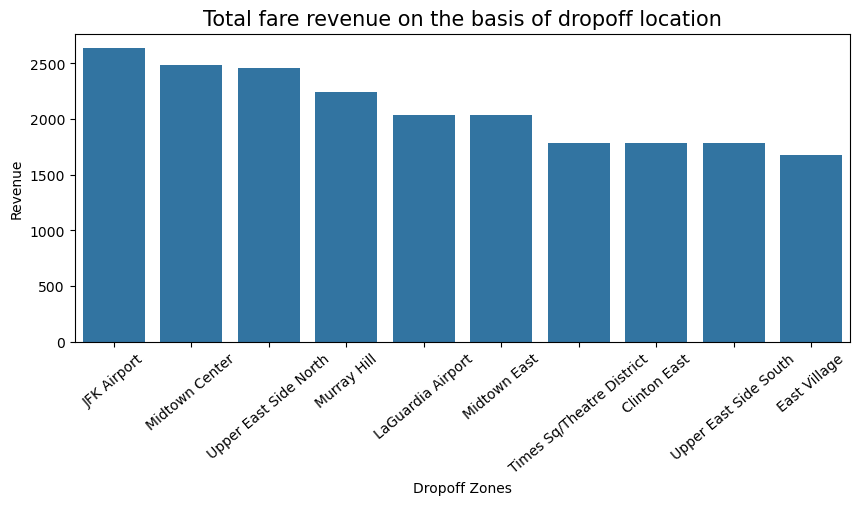

Dropoff zone that generates the highest revenue: JFK Airport


In [7]:
fare_revenue=taxis.groupby("dropoff_zone")["fare"].sum()
print(fare_revenue)
plt.figure(figsize=(10,4))
sns.barplot(x=fare_revenue.sort_values(ascending=False).head(10).index,y=fare_revenue.sort_values(ascending=False).head(10).values)
plt.title("Total fare revenue on the basis of dropoff location",fontsize=15)
plt.xlabel("Dropoff Zones")
plt.ylabel("Revenue")
plt.xticks(rotation=40)
plt.show()

print("Dropoff zone that generates the highest revenue:",fare_revenue.idxmax())

JFK Airport has the highest bar and it generates the highest revenue

 Scatterplot- Investigate the relationship between number of passengers, fare using payment as hue.

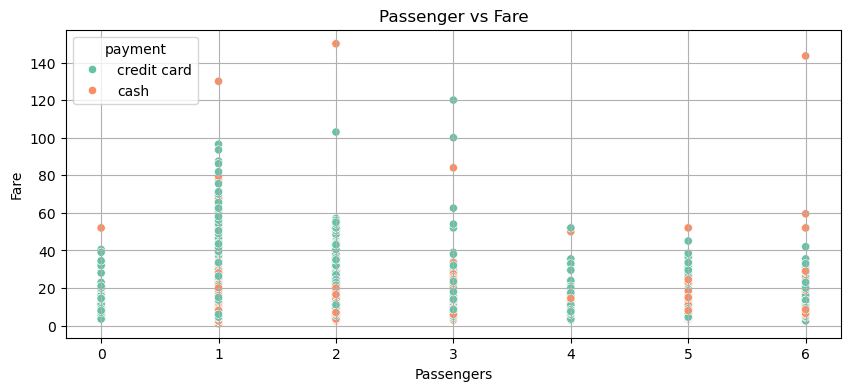

In [9]:
plt.figure(figsize=(10,4))
sns.scatterplot(data=taxis,x="passengers",y="fare",hue="payment",palette="Set2")
plt.title("Passenger vs Fare")
plt.xlabel("Passengers")
plt.ylabel("Fare")
plt.grid()
plt.show()

Most taxi trips are concentrated on 1 showing single passenger trips.
No clear pattern indicating that fare consistenly increase with passenger count.

Pie chart- create a piechart showing the proportion of taxi trips based on day or night pickup period?

period
Day      3679
Night    2754
Name: count, dtype: int64


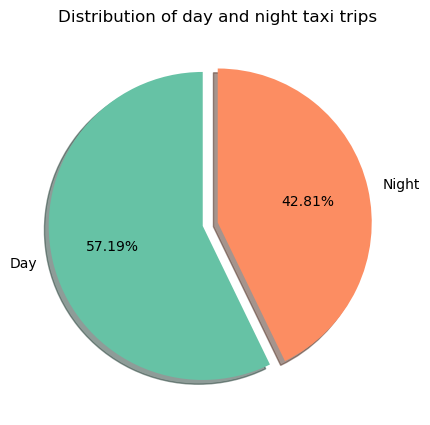

In [16]:
taxis["pickup_hour"]=taxis["pickup"].dt.hour
taxis["period"]=taxis["pickup_hour"].apply(lambda x: "Day" if 6<=x<18 else "Night")
period_counts=taxis["period"].value_counts()
print(period_counts)
largest=period_counts.values.argmax()
explode=[0,0]
explode[largest]=0.1
plt.figure(figsize=(6,5))
plt.pie(period_counts.values,labels=period_counts.index,autopct="%.2f%%",explode=explode,startangle=90,shadow=True,colors=sns.color_palette("Set2"))
plt.title("Distribution of day and night taxi trips")
plt.show()

Day time trips account for 57.19% of total trips, making daytime the dominant period.
Considerable portion of taxi trips also occur at night.

Line plot- Analyze how does the number of taxi trips vary across different days of the week?

pickup_day
Monday        708
Tuesday       825
Wednesday     966
Thursday      905
Friday       1115
Saturday     1046
Sunday        868
Name: count, dtype: int64


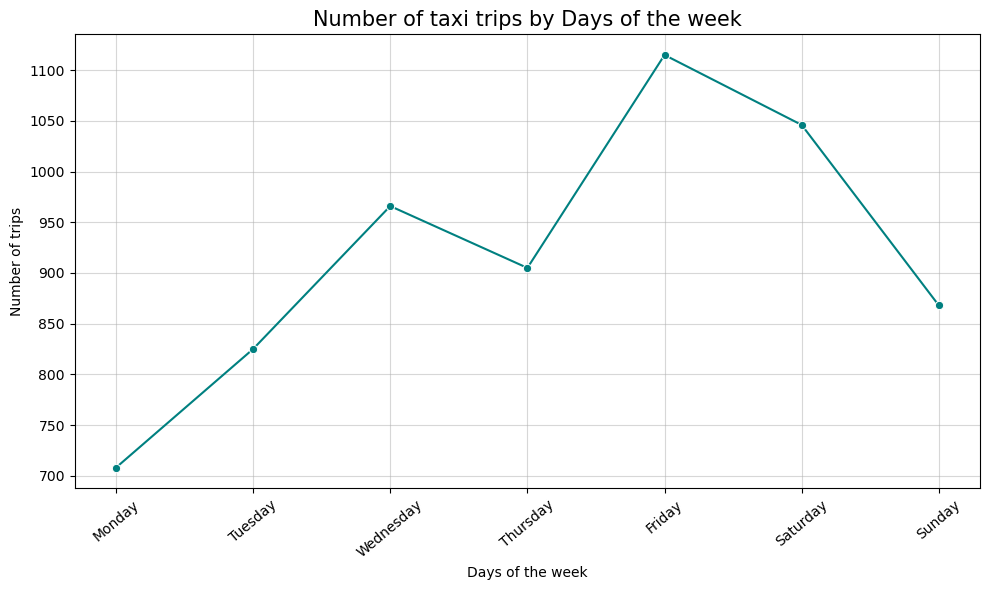

In [19]:
taxis["pickup_day"]=taxis["pickup"].dt.day_name()
day_order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
daily_trips=taxis["pickup_day"].value_counts().reindex(day_order)
print(daily_trips)

plt.figure(figsize=(10,6))
sns.lineplot(x=daily_trips.index,y=daily_trips.values,marker="o",color="teal")
plt.title("Number of taxi trips by Days of the week", fontsize=15)
plt.xlabel("Days of the week")
plt.ylabel("Number of trips")
plt.xticks(rotation=40)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

Friday has the highest number of trips and Monday has the lowest number of trips. Saturday also shows relatively high taxi demand.

# 40) - Analyst Question

. Since, Credit payments are more popular than cash payments, company should continue providing convenient digital payment options and ensure secure transactions.


. Introduce discounts, reward points and special offers for regular customers to encourage repeat usage.


. Monitor the number of trips across different days and hours to allocate taxis efficiently and avoid shortage. 